# Tennis network analysis: full pipeline

Runs every computation of the study in order, from the raw files to the tables and figures of the report,
and shows the main results after each step.

> [!NOTE]
> All cells in this notebook are pre-rendered with the full experimental results, tables, and figures from `results/` and `report/`. You can view them directly on GitHub or in any Jupyter viewer.


**Before running**
1. From the repository root: `python -m venv .venv`, activate it, then `pip install -e ".[dev,notebook]"`.
2. Open this notebook with the `.venv` kernel (VS Code or `jupyter lab`).
3. Choose the settings in the next cell, then *Run All*.

**Running time.** With `QUICK = False` (the settings used in the report) the whole notebook takes about
one to two hours, most of it in the null models. `QUICK = True` uses few samples and finishes in minutes:
use it to check that everything works, **not** for the numbers of the report.

**Outputs.** Every step writes to `results/` and `report/`, overwriting the files committed in the
repository. `git diff --stat` shows what changed; `git checkout -- results report` restores the committed version.

In [1]:
# Settings
# Set RECOMPUTE = True to rerun the entire pipeline from scratch (takes ~1-2 hours due to null models)
# Set RECOMPUTE = False to load and visualize the committed results in results/ and report/ in seconds
RECOMPUTE = False
QUICK = False  # True: few samples, for a quick test run when RECOMPUTE=True
DOWNLOAD = False  # True: download tennis-data.co.uk again (the files are committed)
SKIP = set()  # additional steps to skip when RECOMPUTE is True

In [2]:
import subprocess
import sys
import time

import pandas as pd
from IPython.display import Image, Markdown, display

from tennis_networks.config import REPORT, ROOT, TABLES, load_config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# Arguments of each step: full run (report) and quick run (test only).
ARGS = {
    "analysis": ([], ["--samples", "10"]),
    "hypotheses": (["--null", "200"], ["--null", "20", "--perm", "199"]),
    "structure": ([], ["--sw-samples", "3", "--perm", "199"]),
    "triads": ([], ["--null", "5", "--perm", "199"]),
    "levels": ([], ["--perm", "199"]),
}


def run(module, *extra):
    """Run one pipeline step as `python -m tennis_networks.<module>` and print its output."""
    if not RECOMPUTE:
        print(f"[{module}] (using precomputed results)")
        return
    if module in SKIP:
        print(f"skipped: {module}")
        return
    full, quick = ARGS.get(module, ([], []))
    cmd = [sys.executable, "-m", f"tennis_networks.{module}", *(quick if QUICK else full), *extra]
    start = time.time()
    proc = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
    print(proc.stdout[-4000:])
    if proc.returncode != 0:
        print(proc.stderr[-4000:])
        raise RuntimeError(f"{module} failed with exit code {proc.returncode}")
    print(f"[{module}] done in {(time.time() - start) / 60:.1f} min")


def table(name, **kwargs):
    return pd.read_csv(TABLES / name, **kwargs)


cfg = load_config()
print(f"Repository: {ROOT}")
print(f"Seed: {cfg['seed']}, recompute: {RECOMPUTE}, quick mode: {QUICK}")

Repository: D:\Actual\03_Sviluppo_Software\Repositories\tennis-network-analysis
Seed: 20261115, recompute: False, quick mode: False


## 1. Data

Michieli (2018) networks from MATLAB to CSV edge lists, then the nine comparative networks from
tennis-data.co.uk (edges from loser to winner, weight = wins, walkovers excluded).

In [3]:
if DOWNLOAD:
    run("download")
run("michieli")
run("tennisdata")
display(table("td_networks_summary.csv"))
display(table("td_validity_michieli.csv"))

[michieli] (using precomputed results)
[tennisdata] (using precomputed results)


,network,matches,players,edges,first,last
0,td_atp_2000_2006,20265,796,14995,2000-01-03,2006-11-19
1,td_atp_2007_2012,16114,638,11664,2007-01-01,2012-11-12
2,td_atp_2013_2018,15661,591,11290,2012-12-31,2018-11-18
3,td_atp_2019_2025,16931,624,12582,2018-12-31,2025-11-16
4,td_atp_clay,22117,1176,17914,2000-02-21,2025-07-26
5,td_atp_grass,7693,875,7127,2000-06-12,2025-07-13
6,td_atp_hard,37476,1360,27598,2000-01-03,2025-11-16
7,td_atp_2007_2025,48706,1249,32226,2007-01-01,2025-11-16
8,td_wta_2007_2025,45110,1288,31573,2006-12-31,2025-11-08


,check,total,found_in_michieli,share
0,"ATP loser-winner pairs, 2000 to Aug 2017",32260,31345,0.972
1,"ATP players, 2000 to Aug 2017",1339,1330,0.993


## 2. Reproduction of Michieli (2018)

In [4]:
run("reproduce")
display(table("michieli_reproduction.csv")[["network", "measure", "paper", "ours"]])

[reproduce] (using precomputed results)


,network,measure,paper,ours
0,M1 directed,largest strongly connected component,2428.000,2428.000
1,M1 directed,average distance,3.480,3.470
2,M1 directed,diameter,10.000,9.000
3,M1 directed,top-10 PageRank players shared with the paper,10.000,10.000
4,M3 undirected,connected components,1.000,1.000
5,M3 undirected,average distance,3.340,3.340
6,M3 undirected,diameter,8.000,8.000
7,M3 undirected,average clustering,0.070,0.311
8,M3 undirected,degree assortativity,-0.008,-0.004
9,M4 extended,average distance,3.640,3.630


## 3. Measures of every network

Degrees, PageRank, betweenness, k-cores, components, distances, clustering, assortativity, triad census,
Louvain communities, robustness, and directed null models. The longest step.

In [5]:
run("analysis")
cols = [
    "nodes",
    "edges",
    "density",
    "reciprocity",
    "giant_fraction",
    "avg_path_giant",
    "diameter_giant",
    "max_kcore",
    "modularity",
    "top10_pagerank_share",
    "gini_in_strength",
    "spearman_pagerank_atp_rank",
]
display(table("global_measures.csv", index_col="network")[cols].T)

[analysis] (using precomputed results)


network,example_karate,atp_wins_direct,atp_matches_undirect,td_atp_2000_2006,td_atp_2007_2012,td_atp_2013_2018,td_atp_2019_2025,td_atp_clay,td_atp_grass,td_atp_hard,td_atp_2007_2025,td_wta_2007_2025
nodes,34.000,4245.000,4245.000,796.000,638.000,591.000,624.000,1176.000,875.000,1360.000,1249.000,1288.000
edges,78.000,101436.000,85084.000,14995.000,11664.000,11290.000,12582.000,17914.000,7127.000,27598.000,32226.000,31573.000
density,0.139,0.006,0.009,0.024,0.029,0.032,0.032,0.013,0.009,0.015,0.021,0.019
reciprocity,NaN,0.322,NaN,0.301,0.296,0.298,0.289,0.209,0.086,0.283,0.348,0.323
giant_fraction,1.000,0.572,1.000,0.638,0.646,0.638,0.699,0.694,0.677,0.663,0.665,0.627
avg_path_giant,2.408,3.209,3.340,2.558,2.509,2.434,2.519,2.930,3.282,2.833,2.627,2.604
diameter_giant,5.000,9.000,8.000,7.000,6.000,5.000,6.000,9.000,8.000,7.000,7.000,7.000
max_kcore,4.000,101.000,79.000,73.000,67.000,69.000,64.000,48.000,21.000,70.000,95.000,90.000
modularity,0.428,0.536,0.522,0.151,0.114,0.120,0.124,0.370,0.371,0.381,0.294,0.296
top10_pagerank_share,0.569,0.065,0.020,0.143,0.222,0.194,0.171,0.123,0.143,0.123,0.138,0.101


## 4. Hypotheses H1-H4 (network level)

* H1: prestige more concentrated in 2007-2018 than in 2019-2025 (season permutation)
* H2: assortativity against the configuration model (with undirected clustering and transitivity)
* H3: grass more centralized than clay and hard (match permutation, size-aware)
* H4: WTA prestige less concentrated than ATP (paired seasons)

In [6]:
run("hypotheses")
display(table("hypothesis_tests.csv"))
display(table("null_undirected.csv").pivot(index="network", columns="statistic", values="z"))

[hypotheses] (using precomputed results)


,hypothesis,statistic,comparison,value_a,value_b,diff,p_value,z,perm_mean_diff,p_value_holm,significant_holm
0,H1,top10_pagerank_share,ATP 2007-2018 vs 2019-2025 (season means),0.265,0.234,0.031,0.059,NaN,NaN,0.177,False
1,H1,degree_centralization,ATP 2007-2018 vs 2019-2025 (season means),0.144,0.146,-0.001,0.685,NaN,NaN,0.685,False
2,H2,degree_assortativity,td_atp_2000_2006 vs configuration model,-0.031,-0.183,0.152,0.005,22.358,NaN,0.080,False
3,H2,degree_assortativity,td_atp_2007_2012 vs configuration model,-0.036,-0.186,0.150,0.005,23.607,NaN,0.080,False
4,H2,degree_assortativity,td_atp_2013_2018 vs configuration model,-0.036,-0.175,0.139,0.005,18.200,NaN,0.080,False
5,H2,degree_assortativity,td_atp_2019_2025 vs configuration model,-0.021,-0.173,0.152,0.005,20.350,NaN,0.080,False
6,H2,degree_assortativity,td_atp_clay vs configuration model,0.022,-0.107,0.129,0.005,21.245,NaN,0.080,False
7,H2,degree_assortativity,td_atp_grass vs configuration model,0.099,-0.059,0.158,0.005,15.761,NaN,0.080,False
8,H2,degree_assortativity,td_atp_hard vs configuration model,0.034,-0.117,0.150,0.005,31.064,NaN,0.080,False
9,H2,degree_assortativity,td_wta_2007_2025 vs configuration model,0.022,-0.145,0.167,0.005,33.607,NaN,0.080,False


statistic,avg_clustering,degree_assortativity,transitivity
network,,,
td_atp_2000_2006,-3.374,22.358,28.382
td_atp_2007_2012,-5.642,23.607,27.672
td_atp_2013_2018,-3.596,18.200,21.773
td_atp_2019_2025,-5.872,20.350,25.621
td_atp_clay,14.361,21.245,74.109
td_atp_grass,7.016,15.761,37.298
td_atp_hard,20.334,31.064,120.295
td_wta_2007_2025,5.901,33.607,86.704


## 5. Structure: HITS, structural equivalence, core-periphery, small-world

* **HITS**: authority = beats players who reach the late rounds; hub = goes deep and loses to the champions.
* **Structural equivalence**: players with the same opponents; QAP against the gap in ranking.
* **Core-periphery** (Borgatti-Everett), compared with the k-core.
* **Small-world** sigma against the configuration model.

In [7]:
run("structure")
display(table("structure_summary.csv", index_col="network").T)
hits = table("hits_top10.csv")
display(hits[hits["position"] <= 5].pivot(index=["network", "position"], columns="score", values="player"))
display(table("structural_equivalence_pairs.csv").groupby("network").head(3))
if (TABLES / "rich_club_summary.csv").exists():
    display(Markdown("### Rich-club elite closure (Colizza et al. 2006)"))
    display(table("rich_club_summary.csv"))

[structure] (using precomputed results)


network,td_atp_2000_2006,td_atp_2007_2012,td_atp_2013_2018,td_atp_2019_2025,td_atp_clay,td_atp_grass,td_atp_hard,td_atp_2007_2025,td_wta_2007_2025
authority_pagerank_spearman,0.987,0.985,0.988,0.990,0.970,0.964,0.975,0.981,0.980
authority_rank_spearman,-0.834,-0.834,-0.851,-0.856,-0.776,-0.618,-0.817,-0.843,-0.849
hub_rank_spearman,-0.819,-0.814,-0.858,-0.852,-0.721,-0.608,-0.793,-0.813,-0.827
core_size,132.000,107.000,114.000,127.000,176.000,151.000,216.000,203.000,205.000
core_share,0.166,0.168,0.193,0.204,0.150,0.173,0.159,0.163,0.159
core_fit,0.700,0.718,0.735,0.688,0.468,0.336,0.534,0.637,0.621
density_core,0.637,0.700,0.684,0.615,0.354,0.202,0.409,0.544,0.530
density_core_periphery,0.066,0.083,0.078,0.074,0.044,0.028,0.043,0.057,0.053
density_periphery,0.007,0.009,0.009,0.010,0.006,0.006,0.005,0.006,0.006
continuous_core_fit,0.622,0.636,0.645,0.619,0.449,0.338,0.503,0.581,0.570


score                         authority                hub
network          position                                 
td_atp_2000_2006 1           Federer R.          Mirnyi M.
                 2            Hewitt L.      Srichaphan P.
                 3           Roddick A.          Hrbaty D.
                 4         Ferrero J.C.      Schuettler R.
                 5              Moya C.         Malisse X.
td_atp_2007_2012 1          Djokovic N.        Verdasco F.
                 2             Nadal R.          Ferrer D.
                 3           Federer R.         Berdych T.
                 4            Murray A.           Lopez F.
                 5            Ferrer D.        Wawrinka S.
td_atp_2007_2025 1          Djokovic N.        Wawrinka S.
                 2             Nadal R.         Berdych T.
                 3           Federer R.        Verdasco F.
                 4            Murray A.           Cilic M.
                 5            Ferrer D.         Gasquet R.
td_atp_2013_2018 1          Djokovic N.         Berdych T.
                 2             Nadal R.        Dimitrov G.
                 3           Federer R.          Ferrer D.
                 4            Murray A.        Anderson K.
                 5         Nishikori K.       Nishikori K.
td_atp_2019_2025 1          Medvedev D.          Rublev A.
                 2            Sinner J.          Zverev A.
                 3          Djokovic N.       De Minaur A.
                 4         Tsitsipas S.       Khachanov K.
                 5            Zverev A.          Sonego L.
td_atp_clay      1             Nadal R.          Ferrer D.
                 2            Ferrer D.         Almagro N.
                 3           Almagro N.        Montanes A.
                 4          Djokovic N.        Verdasco F.
                 5           Robredo T.         Fognini F.
td_atp_grass     1           Federer R.         Youzhny M.
                 2          Djokovic N.   Kohlschreiber P.
                 3            Murray A.       Mannarino A.
                 4             Lopez F.          Hewitt L.
                 5             Cilic M.         Gasquet R.
td_atp_hard      1          Djokovic N.         Berdych T.
                 2           Federer R.         Gasquet R.
                 3             Nadal R.           Lopez F.
                 4            Murray A.        Wawrinka S.
                 5           Berdych T.          Ferrer D.
td_wta_2007_2025 1         Wozniacki C.  Pavlyuchenkova A.
                 2          Williams S.          Cornet A.
                 3          Azarenka V.       Radwanska A.
                 4           Kvitova P.          Kerber A.
                 5         Radwanska A.       Wozniacki C.

,network,player_a,player_b,cosine,rank_a,rank_b
0,td_atp_2000_2006,Ljubicic I.,Hewitt L.,0.775,35.0,6.0
1,td_atp_2000_2006,Gaudio G.,Moya C.,0.770,26.0,18.0
2,td_atp_2000_2006,Federer R.,Schuettler R.,0.764,3.0,38.0
10,td_atp_2007_2012,Berdych T.,Ferrer D.,0.825,10.0,7.0
11,td_atp_2007_2012,Murray A.,Djokovic N.,0.821,4.0,3.0
12,td_atp_2007_2012,Djokovic N.,Del Potro J.M.,0.820,3.0,12.0
20,td_atp_2013_2018,Berdych T.,Nishikori K.,0.820,7.0,9.0
21,td_atp_2013_2018,Federer R.,Murray A.,0.799,3.0,3.0
22,td_atp_2013_2018,Raonic M.,Dimitrov G.,0.782,10.0,14.0
30,td_atp_2019_2025,Auger-Aliassime F.,Rublev A.,0.782,19.0,8.0


### Rich-club elite closure (Colizza et al. 2006)

,network,peak_k,elite_nodes,phi_obs,phi_null,rho_rich_peak,z_peak,thresholds_tested,z_max_null_95,p_max,p_pointwise,null_samples
0,td_atp_2000_2006,100,96,0.776,0.698,1.112,18.300,174,2.811,0.005,0.005,200
1,td_atp_2007_2012,88,90,0.778,0.711,1.095,16.103,151,2.802,0.005,0.005,200
2,td_atp_2013_2018,84,103,0.730,0.679,1.076,16.343,144,2.805,0.005,0.005,200
3,td_atp_2019_2025,69,132,0.599,0.564,1.061,16.117,156,2.892,0.005,0.005,200
4,td_atp_clay,82,119,0.482,0.422,1.141,16.492,188,2.904,0.005,0.005,200
5,td_atp_grass,48,65,0.386,0.305,1.265,11.820,87,3.035,0.005,0.005,200
6,td_atp_hard,120,120,0.607,0.518,1.171,21.585,237,3.014,0.005,0.005,200
7,td_atp_2007_2025,144,128,0.727,0.638,1.139,24.293,281,2.873,0.005,0.005,200
8,td_wta_2007_2025,144,122,0.733,0.628,1.166,27.865,264,3.003,0.005,0.005,200


## 6. Triad census and H5

Ratio of cyclic triads (A beats B, B beats C, C beats A) to transitive ones: 1/3 with random results,
lower when the hierarchy is consistent. H5: the hierarchy was more rigid in 2007-2012.

[triads] (using precomputed results)


,network,cyclic_ratio,null_mean,z,p_empirical
0,td_atp_2000_2006,0.211,0.255,-15.260,0.005
1,td_atp_2007_2012,0.172,0.223,-16.112,0.005
2,td_atp_2013_2018,0.196,0.245,-15.740,0.005
3,td_atp_2019_2025,0.221,0.258,-13.212,0.005
4,td_atp_clay,0.215,0.270,-17.587,0.005
5,td_atp_grass,0.197,0.253,-6.827,0.005
6,td_atp_hard,0.201,0.266,-33.419,0.005
7,td_atp_2007_2025,0.202,0.263,-38.699,0.005
8,td_wta_2007_2025,0.209,0.271,-40.786,0.005


,hypothesis,statistic,comparison,value_a,value_b,diff,p_value,p_value_holm,significant_holm
0,H5,cyclic_ratio,ATP seasons 2007-2012 vs 2000-2006 and 2013-2025,0.184,0.211,-0.027,0.01,0.02,True
1,H5 (tours),cyclic_ratio,"WTA vs ATP, paired season differences 2007-2025",0.206,0.198,0.008,0.10,0.10,False


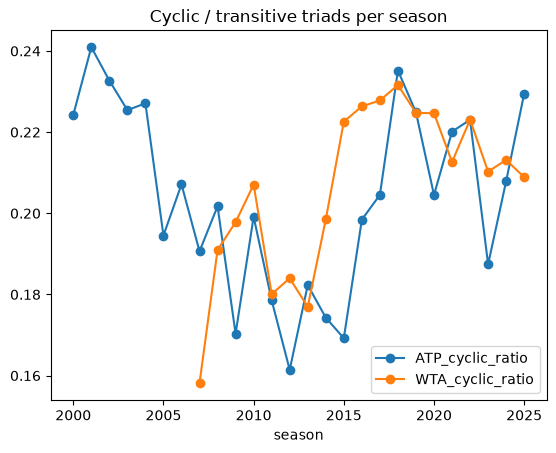

In [8]:
run("triads")
display(table("triads_networks.csv")[["network", "cyclic_ratio", "null_mean", "z", "p_empirical"]])
display(table("triads_h5.csv"))
table("triads_by_season.csv", index_col="season").plot(marker="o", title="Cyclic / transitive triads per season");

## 7. Hypotheses at the monadic, dyadic and mixed levels (slide L04)

* H6 (monadic): PageRank explains the ranking beyond the number of wins (permutation regression)
* H7 (dyadic): head-to-head dominance carries over between surfaces (QAP)
* H8 (mixed): players with the same surface profile meet more often (QAP)

In [9]:
run("levels")
display(table("levels_tests.csv"))
profiles = table("surface_profiles.csv", index_col="player")
display(profiles["profile"].value_counts())

[levels] (using precomputed results)


,hypothesis,level,comparison,statistic,value,p_value,n,note,p_value_holm,significant_holm
0,H6,monadic,td_atp_2000_2006: log(ranking) on log(PageRank...,beta log PageRank,-0.628,0.003,518,R2 = 0.622; max |r| = 0.972; condition number ...,0.015,True
1,H6,monadic,td_atp_2000_2006: log(ranking) on log(PageRank...,beta log wins,-0.164,0.388,518,R2 = 0.622; max |r| = 0.972; condition number ...,1.000,False
2,H6,monadic,td_atp_2007_2012: log(ranking) on log(PageRank...,beta log PageRank,-0.773,0.001,419,R2 = 0.758; max |r| = 0.965; condition number ...,0.012,True
3,H6,monadic,td_atp_2007_2012: log(ranking) on log(PageRank...,beta log wins,-0.100,0.620,419,R2 = 0.758; max |r| = 0.965; condition number ...,1.000,False
4,H6,monadic,td_atp_2013_2018: log(ranking) on log(PageRank...,beta log PageRank,-0.827,0.001,387,R2 = 0.784; max |r| = 0.966; condition number ...,0.012,True
5,H6,monadic,td_atp_2013_2018: log(ranking) on log(PageRank...,beta log wins,-0.060,0.770,387,R2 = 0.784; max |r| = 0.966; condition number ...,1.000,False
6,H6,monadic,td_atp_2019_2025: log(ranking) on log(PageRank...,beta log PageRank,-0.749,0.001,439,R2 = 0.731; max |r| = 0.970; condition number ...,0.012,True
7,H6,monadic,td_atp_2019_2025: log(ranking) on log(PageRank...,beta log wins,-0.110,0.601,439,R2 = 0.731; max |r| = 0.970; condition number ...,1.000,False
8,H7,dyadic,"head-to-head balance on Clay vs on Hard, ATP 2...",QAP Pearson r,0.149,0.001,329,mean permuted r = -0.000,0.012,True
9,H7,dyadic,"head-to-head balance on Grass vs on Hard, ATP ...",QAP Pearson r,0.124,0.001,306,mean permuted r = 0.000,0.012,True


profile
all-round    204
clay          76
hard          49
Name: count, dtype: int64

## 8. Report tables, figures and word count

[report_assets] (using precomputed results)
[wordcount] (using precomputed results)


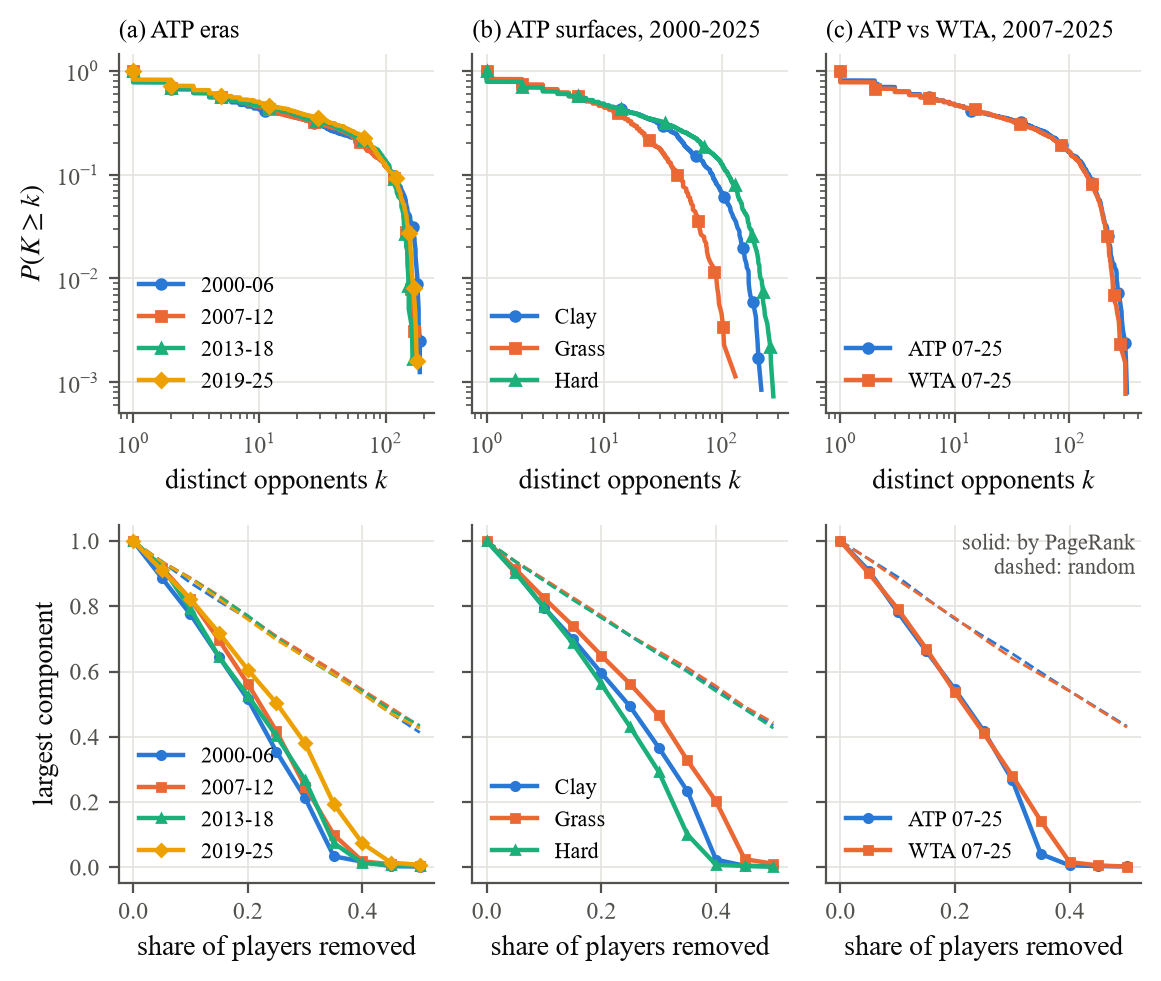

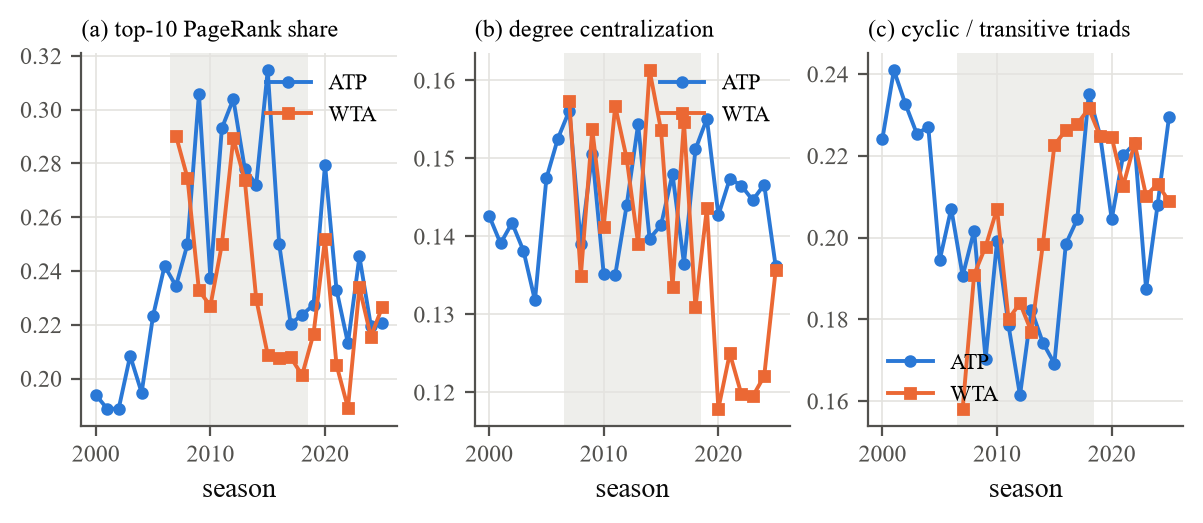

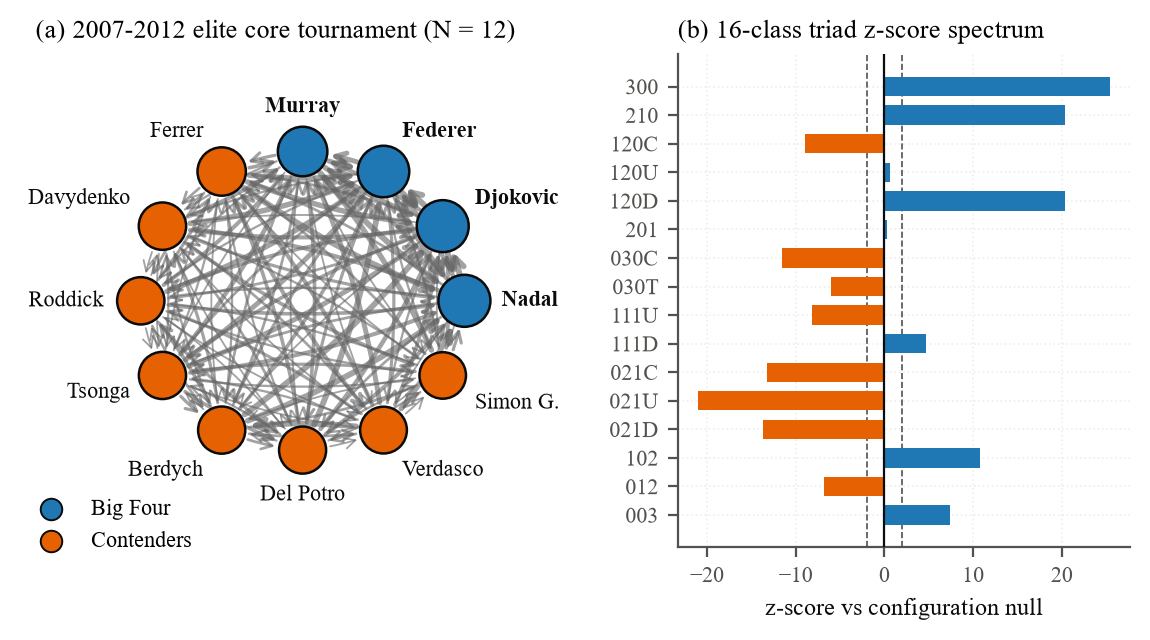

In [10]:
run("report_assets")
run("wordcount")
for name in ("fig_topology", "fig_yearly", "fig_network_core_2007_2012"):
    display(Image(filename=str(REPORT / "figures" / f"{name}.png")))

## 9. Summary of all hypotheses

In [11]:
h = table("hypothesis_tests.csv")
h5 = table("triads_h5.csv")
lv = table("levels_tests.csv")
summary = pd.concat(
    [
        h[["hypothesis", "statistic", "comparison", "value_a", "value_b", "p_value"]],
        h5[["hypothesis", "statistic", "comparison", "value_a", "value_b", "p_value"]],
        lv.rename(columns={"value": "value_a"})[["hypothesis", "statistic", "comparison", "value_a", "p_value"]],
    ],
    ignore_index=True,
)
display(summary)
display(Markdown(f"Results written to `{TABLES}` and `{REPORT}`. Check `git diff --stat` before committing."))

,hypothesis,statistic,comparison,value_a,value_b,p_value
0,H1,top10_pagerank_share,ATP 2007-2018 vs 2019-2025 (season means),0.265,0.234,0.059
1,H1,degree_centralization,ATP 2007-2018 vs 2019-2025 (season means),0.144,0.146,0.685
2,H2,degree_assortativity,td_atp_2000_2006 vs configuration model,-0.031,-0.183,0.005
3,H2,degree_assortativity,td_atp_2007_2012 vs configuration model,-0.036,-0.186,0.005
4,H2,degree_assortativity,td_atp_2013_2018 vs configuration model,-0.036,-0.175,0.005
5,H2,degree_assortativity,td_atp_2019_2025 vs configuration model,-0.021,-0.173,0.005
6,H2,degree_assortativity,td_atp_clay vs configuration model,0.022,-0.107,0.005
7,H2,degree_assortativity,td_atp_grass vs configuration model,0.099,-0.059,0.005
8,H2,degree_assortativity,td_atp_hard vs configuration model,0.034,-0.117,0.005
9,H2,degree_assortativity,td_wta_2007_2025 vs configuration model,0.022,-0.145,0.005


Results written to `D:\Actual\03_Sviluppo_Software\Repositories\tennis-network-analysis\results\tables` and `D:\Actual\03_Sviluppo_Software\Repositories\tennis-network-analysis\report`. Check `git diff --stat` before committing.